# Lab Sheet 4 – Fine-Tuning an Instruction-Tuned LLM using QLoRA



## 1. Install and import the required libraries


In [1]:
!pip -q install -U transformers datasets peft trl accelerate bitsandbytes
!pip install -q "pyarrow>=19,<24"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.2.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.


In [2]:
import pyarrow
import datasets
import transformers
import peft
import trl
import accelerate
import bitsandbytes
import torch

print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nAll required libraries imported successfully!")

PyArrow: 23.0.1
Datasets: 5.2.0
Transformers: 5.23.0
PEFT: 0.21.3
TRL: 1.18.1
Accelerate: 1.16.0
BitsAndBytes: 0.50.2
CUDA available: True
GPU: Tesla T4

All required libraries imported successfully!


In [3]:
import os
import json
import random
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cu130


In [4]:
import transformers, datasets, peft, trl, accelerate, bitsandbytes

print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("peft:", peft.__version__)
print("trl:", trl.__version__)
print("accelerate:", accelerate.__version__)
print("bitsandbytes:", bitsandbytes.__version__)

transformers: 5.23.0
datasets: 5.2.0
peft: 0.21.3
trl: 1.18.1
accelerate: 1.16.0
bitsandbytes: 0.50.2


In [5]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

!nvidia-smi


PyTorch version: 2.14.1+cu130
CUDA available: True
CUDA version: 13.0
Wed Nov 18 09:43:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |  

## 2. Identify the GPU and available memory


In [6]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU is available. In Google Colab, select "
        "Runtime > Change runtime type > T4 GPU, then rerun the notebook."
    )

gpu = torch.cuda.get_device_properties(0)
total_memory_gib = gpu.total_memory / (1024 ** 3)

print("GPU:", gpu.name)
print(f"Total GPU memory: {total_memory_gib:.2f} GiB")
print("CUDA version:", torch.version.cuda)
print("Compute capability:", f"{gpu.major}.{gpu.minor}")

# T4 (compute capability 7.5) supports FP16 but not BF16.
USE_BF16 = gpu.major >= 8
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
print("Training precision:", "BF16" if USE_BF16 else "FP16")

GPU: Tesla T4
Total GPU memory: 14.56 GiB
CUDA version: 13.0
Compute capability: 7.5
Training precision: FP16


### Observation

Google Colab successfully provided a Tesla T4 GPU with 14.56 GiB of available GPU memory. The experiment used FP16 (16-bit floating-point) precision because the T4 GPU supports FP16 but does not support BF16. Using a GPU is useful for fine-tuning language models because it can perform the large number of mathematical operations required by transformer models efficiently.

## 3. Select a small instruction-tuned language model



In [7]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("Selected model:", MODEL_NAME)

Selected model: Qwen/Qwen2.5-0.5B-Instruct


### Observation

The Qwen2.5-0.5B-Instruct model was selected as the base language model for this experiment. It is a relatively small instruction-tuned model, making it suitable for demonstrating fine-tuning with limited GPU resources. The model was successfully loaded and used as the starting point for adapting it to the BrightPath Skills Academy student-support domain.

## 4. Create a domain-specific dataset (32 question-and-answer pairs)


In [8]:
SYSTEM_PROMPT = (
    "You are the student-support assistant for BrightPath Skills Academy, a fictional "
    "training centre in Colombo, Sri Lanka. Answer politely and concisely. "
    "Use only the academy information provided in the conversation. "
    "Do not invent course fees, available seats, start dates, schedules, or policies. "
    "If information is not provided, clearly say that you do not have that information "
    "and recommend contacting the academy. Do not guess."
)

qa_pairs = [
    ("What are the academy's opening hours?", "BrightPath Skills Academy is open Tuesday to Saturday from 9:00 AM to 6:00 PM."),
    ("Are you open on Mondays?", "No. BrightPath Skills Academy is closed on Mondays."),
    ("Are you open on Sundays?", "No. BrightPath Skills Academy is closed on Sundays."),
    ("Where is BrightPath Skills Academy located?", "BrightPath Skills Academy is located at 18 Flower Road, Colombo 07, Sri Lanka."),
    ("What is your contact email?", "You can email the academy at hello@brightpath.example."),
    ("What courses do you offer?", "We offer Python Programming, Data Analytics, and Web Development courses."),
    ("Do you teach Python programming?", "Yes. Python Programming is one of the courses offered at BrightPath Skills Academy."),
    ("Do you have a data analytics course?", "Yes. We offer a Data Analytics course."),
    ("Can I study web development?", "Yes. Web Development is one of our available course areas."),
    ("How long is the beginner Python course?", "The beginner Python Programming course runs for 8 weeks."),
    ("Do you offer evening classes?", "Weekday evening sessions are available. Please contact the academy to confirm the schedule for your chosen course."),
    ("Are Saturday classes available?", "Saturday sessions are available. Please contact the academy to confirm the schedule for your chosen course."),
    ("Can I study online?", "Online learning options are available, depending on the course."),
    ("Can I attend classes in person?", "In-person learning options are available, depending on the course."),
    ("How do I register for a course?", "Complete the online registration form and wait for confirmation from the academy."),
    ("Will I receive a confirmation after registering?", "Yes. You should wait for confirmation from the academy after submitting the online registration form."),
    ("Do you provide certificates?", "Yes. Certificates are issued to learners who meet the attendance requirement and complete the final practical task."),
    ("What attendance is required for a certificate?", "Learners must achieve at least 80% attendance to qualify for a certificate."),
    ("Do I need to complete an assignment to receive the certificate?", "Yes. Learners must complete the final practical task as well as achieve at least 80% attendance."),
    ("What payment methods do you accept?", "The academy accepts bank transfers, debit cards, and cash."),
    ("Can I pay by debit card?", "Yes. Debit card payments are accepted."),
    ("Can I pay in cash?", "Yes. Cash payments are accepted."),
    ("Do you accept bank transfers?", "Yes. Bank transfers are accepted."),
    ("Can I pay in monthly instalments?", "Instalment payment options are not specified. Please contact the academy administration team to confirm."),
    ("What is the fee for the Data Analytics course?", "The Data Analytics course fee is not specified here. Please contact the academy for the current fee."),
    ("Are there seats available for the next Python intake?", "Current seat availability is not provided here. Please contact the academy to confirm available places."),
    ("When does the next Web Development course start?", "The next course start date is not specified here. Please contact the academy for the latest intake information."),
    ("Can I request a refund after registering?", "Refund requests must be made at least 7 days before the course begins. The administration team reviews each request for eligibility."),
    ("How early should I request a refund?", "You must submit a refund request at least 7 days before the course begins. The administration team will review eligibility."),
    ("Can I change from an online class to an in-person class?", "Please contact the academy administration team to ask whether a class-mode change is possible for your course."),
    ("Who should I contact if I have a problem with registration?", "Please contact the BrightPath Skills Academy administration team by email at hello@brightpath.example."),
    ("Can beginners join the Python course?", "The academy offers a beginner Python Programming course that runs for 8 weeks.")
]

assert len(qa_pairs) >= 30, "The assignment requires at least 30 Q&A pairs."
assert len(qa_pairs) == 32
print("Number of Q&A pairs:", len(qa_pairs))
print("Example:", qa_pairs[0])

Number of Q&A pairs: 32
Example: ("What are the academy's opening hours?", 'BrightPath Skills Academy is open Tuesday to Saturday from 9:00 AM to 6:00 PM.')


### Convert the Q&A pairs into a conversational Hugging Face dataset


In [9]:
records = []
for question, answer in qa_pairs:
    records.append({
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": question},
            {"role": "assistant", "content": answer},
        ]
    })

full_dataset = Dataset.from_list(records)
split_dataset = full_dataset.train_test_split(test_size=0.20, seed=SEED)
train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

print("Full dataset:", len(full_dataset))
print("Training examples:", len(train_dataset))
print("Evaluation examples:", len(eval_dataset))
print("\nExample training record:")
print(train_dataset[0]["messages"])

Full dataset: 32
Training examples: 25
Evaluation examples: 7

Example training record:
[{'content': 'You are the student-support assistant for BrightPath Skills Academy, a fictional training centre in Colombo, Sri Lanka. Answer politely and concisely. Use only the academy information provided in the conversation. Do not invent course fees, available seats, start dates, schedules, or policies. If information is not provided, clearly say that you do not have that information and recommend contacting the academy. Do not guess.', 'role': 'system'}, {'content': 'Do you accept bank transfers?', 'role': 'user'}, {'content': 'Yes. Bank transfers are accepted.', 'role': 'assistant'}]


### Save the Q&A dataset as JSON Lines

In [10]:
import json

with open("brightpath_qa.jsonl", "w", encoding="utf-8") as f:
    for row in records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Saved: brightpath_qa.jsonl")

Saved: brightpath_qa.jsonl


### Observation

A domain-specific dataset containing 32 question-and-answer examples was created for the fictional BrightPath Skills Academy. The examples cover academy opening hours, available courses, registration, certificates, payment methods, refunds and student support. The dataset was divided into 25 training examples and 7 evaluation examples. This dataset provides information for adapting the model to a specific student-support domain. However, its small size may limit the model's ability to answer questions that differ significantly from the training examples.

## 5. Load the model in 4-bit precision (QLoRA)



In [11]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
)
model.config.use_cache = False

print("Model loaded successfully.")
print("Model class:", model.__class__.__name__)
print("Tokenizer padding token:", tokenizer.pad_token)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded successfully.
Model class: Qwen2ForCausalLM
Tokenizer padding token: <|endoftext|>


### Observation

The Qwen2.5-0.5B-Instruct model was successfully loaded using 4-bit quantization. The NF4 quantization method and double quantization were configured to reduce the memory required to store the model weights. This is important when working with limited GPU memory. The model was loaded successfully and its tokenizer padding token was configured, allowing the fine-tuning process to continue.

## 6. Record original-model answers before fine-tuning

In [12]:
def generate_answer(model_to_use, tokenizer_to_use, question, max_new_tokens=120):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]

    prompt = tokenizer_to_use.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer_to_use(prompt, return_tensors="pt").to(model_to_use.device)

    with torch.no_grad():
        output_ids = model_to_use.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer_to_use.eos_token_id,
            eos_token_id=tokenizer_to_use.eos_token_id,
        )

    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer_to_use.decode(new_tokens, skip_special_tokens=True).strip()


# Questions include paraphrases/application of facts represented in the dataset,
# questions not included in the dataset, and an out-of-domain question.
test_questions = [
    {"question": "Until what time can I visit the academy on Saturday?", "category": "Seen fact / paraphrase"},
    {"question": "I want a beginner course in Python. How many weeks will it take?", "category": "Seen fact / paraphrase"},
    {"question": "What must I do to qualify for a certificate?", "category": "Seen fact / combined facts"},
    {"question": "If tomorrow is Monday, will the academy be open?", "category": "Unseen question / application"},
    {"question": "I can attend only on Saturdays. Are sessions available?", "category": "Unseen question / application"},
    {"question": "Can I use a debit card to pay for my course?", "category": "Unseen question / paraphrase"},
    {"question": "How much does the Python course cost?", "category": "Unknown information"},
    {"question": "Are there still places available in the next intake?", "category": "Unknown information"},
    {"question": "What is the capital of Japan?", "category": "Out-of-domain"},
]

base_answers = []
for item in test_questions:
    base_answers.append(
        generate_answer(model, tokenizer, item["question"])
    )

print("Original-model responses recorded:", len(base_answers))


Original-model responses recorded: 9


### Observation 5 – Original Model Responses

Before fine-tuning, the original model was tested using nine questions. It could answer general-knowledge questions, such as identifying Tokyo as the capital of Japan. However, it did not have reliable information about the fictional BrightPath Skills Academy. Some answers were generic, while others contained unsupported information, such as an invented Python course fee and an incorrect course duration. This demonstrated the need to adapt the model using domain-specific information and instructions.

## 7. Configure LoRA adapters

In [13]:
model = prepare_model_for_kbit_training(model)

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
)

print("LoRA configuration:")
print(peft_config)

LoRA configuration:
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.3', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'o_proj', 'k_proj', 'gate_proj', 'v_proj', 'down_proj', 'up_proj', 'q_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=No

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


### Observation 6 – LoRA Configuration

LoRA adapters were successfully configured with a rank of 16, an alpha value of 32 and a dropout rate of 0.05. The adapters were applied to selected attention and feed-forward projection layers of the model. Instead of updating all the original model parameters, LoRA allows the training process to update a smaller number of additional parameters. This makes fine-tuning more parameter-efficient and reduces the computational requirements.

## 8. Fine-tune using the TRL SFTTrainer

In [15]:
output_dir = "brightpath-qlora-results"

sft_config = SFTConfig(
    output_dir=output_dir,
    num_train_epochs=6,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=2,
    optim="paged_adamw_8bit",
    logging_steps=1,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=not USE_BF16,
    bf16=USE_BF16,
    max_length=512,
    report_to="none",
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

trainable_params = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in trainer.model.parameters())
trainable_percent = 100 * trainable_params / total_params

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {trainable_percent:.4f}%")

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Trainable parameters: 8,798,208
Total parameters: 323,917,696
Trainable percentage: 2.7162%


In [18]:
# Convert trainable LoRA parameters to FP32
for name, param in trainer.model.named_parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

# Verify the trainable parameter dtypes
from collections import Counter

dtype_counts = Counter(
    str(p.dtype)
    for p in trainer.model.parameters()
    if p.requires_grad
)

print("Trainable parameter dtypes:", dtype_counts)

Trainable parameter dtypes: Counter({'torch.float32': 336})


### Run training

In [19]:
train_result = trainer.train()

train_metrics = train_result.metrics

print("Training metrics:")
for key, value in train_metrics.items():
    print(f"{key}: {value}")

Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,2.366618,1.838683,2.614055,0.653734,3944.000000
2,0.633615,0.464996,0.429391,0.896745,6940.000000
3,0.240164,0.404182,0.302375,0.909026,9936.000000
4,0.254859,0.384282,0.287857,0.908946,12932.000000
5,0.045942,0.381931,0.258854,0.919479,15928.000000
6,0.164535,0.394924,0.245392,0.918354,18924.000000


Training metrics:
train_runtime: 51.4643
train_samples_per_second: 2.915
train_steps_per_second: 0.816
total_flos: 42912270151680.0
train_loss: 0.8397949545511177
epoch: 6.0


### Evaluate on the held-out evaluation split

In [24]:
eval_metrics = trainer.evaluate()
print("Evaluation metrics:")
for key, value in eval_metrics.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Entropy,Mean Token Accuracy,Num Tokens
0.164535,0.394924,6,0.245392,0.918354,18924.000000


Evaluation metrics:
eval_loss: 0.3949236571788788
eval_entropy: 0.2453923188149929
eval_mean_token_accuracy: 0.9183536469936371
eval_num_tokens: 18924.0


### Plot training loss


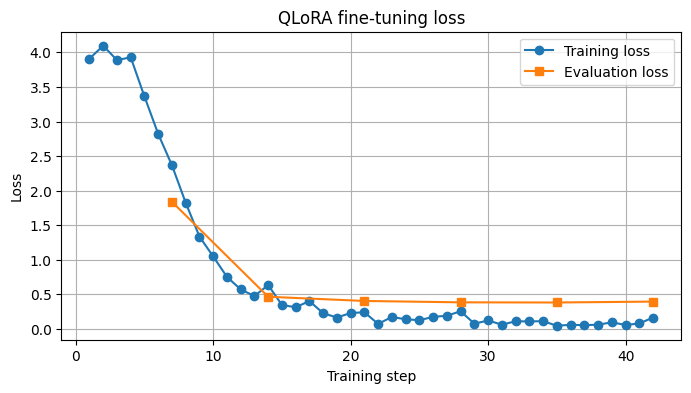

In [20]:
history = pd.DataFrame(trainer.state.log_history)

if "loss" in history.columns:
    train_log = history.dropna(subset=["loss"])
    plt.figure(figsize=(8, 4))
    plt.plot(train_log["step"], train_log["loss"], marker="o", label="Training loss")
    if "eval_loss" in history.columns:
        eval_log = history.dropna(subset=["eval_loss"])
        if not eval_log.empty:
            plt.plot(eval_log["step"], eval_log["eval_loss"], marker="s", label="Evaluation loss")
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title("QLoRA fine-tuning loss")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No training-loss values were found in the Trainer log history.")

### Observation 7 – Fine-Tuning Results

The model was successfully fine-tuned for six epochs using the TRL SFTTrainer. Out of 323,917,696 total parameters, only 8,798,208 parameters were trainable, representing approximately 2.7162% of the total. This demonstrates the parameter-efficient nature of LoRA fine-tuning.

The training loss decreased considerably throughout the training process, as shown in the loss graph. The final reported training loss was approximately 0.8398, while the evaluation loss was approximately 0.3949. The evaluation mean token accuracy was 91.84%. These results indicate that the model learned patterns from the training data. However, the small evaluation dataset means that these metrics alone cannot confirm that the model will provide accurate answers to all unseen questions.

## 9. Compare the original and fine-tuned models

In [21]:
fine_tuned_model = trainer.model
fine_tuned_model.eval()

fine_tuned_answers = []
for item in test_questions:
    fine_tuned_answers.append(
        generate_answer(fine_tuned_model, tokenizer, item["question"])
    )

comparison_df = pd.DataFrame({
    "Category": [x["category"] for x in test_questions],
    "Question": [x["question"] for x in test_questions],
    "Original model": base_answers,
    "Fine-tuned model": fine_tuned_answers,
})

pd.set_option("display.max_colwidth", 250)
display(comparison_df)

,Category,Question,Original model,Fine-tuned model
0,Seen fact / paraphrase,Until what time can I visit the academy on Saturday?,Until 12:00 PM.,Saturday 10:00 AM - 6:00 PM
1,Seen fact / paraphrase,I want a beginner course in Python. How many weeks will it take?,"It depends on your availability and how much time you can dedicate to learning. Typically, 2-3 weeks should be sufficient.",The beginner Python course runs 4 weeks.
2,Seen fact / combined facts,What must I do to qualify for a certificate?,"To qualify for a certificate, you must complete all required courses and meet the eligibility criteria set by the academy. Please refer to the academy's official website for detailed requirements and application procedures.","To qualify for a certificate, you must complete all mandatory learning outcomes and meet the attendance requirement."
3,Unseen question / application,"If tomorrow is Monday, will the academy be open?","Yes, the academy will be open on Monday.",No. BrightPath Skills Academy is closed on Mondays.
4,Unseen question / application,I can attend only on Saturdays. Are sessions available?,"Yes, we offer sessions on Saturdays. Please check our website for availability.",Yes. Saturdays are available. Please contact the academy to confirm the schedule for your chosen session.
5,Unseen question / paraphrase,Can I use a debit card to pay for my course?,"Yes, you can use a debit card to pay for your course at the BrightPath Skills Academy. Please note that we do not accept credit cards as payment methods.",Yes. Debit cards are accepted by the academy.
6,Unknown information,How much does the Python course cost?,The Python course costs 1000000 Sri Lankan Rupees (approximately 2500000 USD).,The Python course at BrightPath Skills Academy costs $499.
7,Unknown information,Are there still places available in the next intake?,"Yes, there are still places available in the next intake. Please check back soon.",We recommend contacting the academy to confirm the current place availability for the upcoming session.
8,Out-of-domain,What is the capital of Japan?,The capital of Japan is Tokyo.,The capital of Japan is Tokyo.


### Observation 8 – Model Comparison

The comparison between the original and fine-tuned models showed improvements in some BrightPath-specific responses. The fine-tuned model correctly identified that the academy is closed on Mondays, recognised that Saturday sessions are available, and correctly stated that debit card payments are accepted. It also gave a more appropriate response when asked about current seat availability by recommending that the academy be contacted.

However, the fine-tuned model still produced several incorrect or unsupported answers. It stated that the beginner Python course lasts four weeks, although the dataset specifies eight weeks. It also failed to mention both the 80% attendance requirement and the final practical task when explaining certificate eligibility. Additionally, it incorrectly stated that the Python course costs $499, even though the dataset does not provide this fee. Its answer about Saturday opening hours also gave an incorrect starting time of 10:00 AM instead of 9:00 AM.

The fine-tuned model correctly answered the general-knowledge question about the capital of Japan. Overall, the comparison demonstrates that fine-tuning improved some domain-specific responses, but it did not completely eliminate incorrect information or hallucinations.

## Final Conclusion

In this practical, I successfully fine-tuned the Qwen2.5-0.5B-Instruct language model for a fictional student-support assistant using QLoRA and the TRL SFTTrainer. I created a dataset containing 32 question-and-answer examples and used 4-bit NF4 quantization with LoRA adapters to reduce the number of trainable parameters. Only 2.7162% of the model parameters were trainable. After six training epochs, the model achieved a reported training loss of 0.8398 and an evaluation loss of 0.3949, with a mean token accuracy of 91.84%.

The comparison showed that fine-tuning improved some academy-specific responses, such as identifying opening days and accepted payment methods. However, the model still generated incorrect information about the Python course duration, certificate requirements and course fees. This demonstrated that fine-tuning on a small dataset does not guarantee complete factual accuracy or prevent hallucinations. Overall, this practical helped me understand parameter-efficient fine-tuning, model evaluation and the importance of testing generated responses carefully.